In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, FancyArrowPatch, Polygon

from plot_style import apply

OUTPUT = Path("figs") / "Fig2.pdf"

apply()

In [2]:
O = np.array([0.20, 0.13])
EX = np.array([0.72, -0.05])
EY = np.array([0.30, 0.22])
EZ = np.array([0.00, 0.66])


def P(x, y, z):
    return O + x * EX + y * EY + z * EZ


VERTICES = [(x, y, z) for x in (0, 1) for y in (0, 1) for z in (0, 1)]
CUBE_EDGES = []
for a in VERTICES:
    for b in VERTICES:
        if sum(abs(a[i] - b[i]) for i in range(3)) == 1 and a < b:
            CUBE_EDGES.append((a, b))

ACCENT = "#E08888"
TRIPLET = "#6B9AC4"
PAIRPAIR = "#7DB892"
WIRE = "#A8B8C8"
WIRE_LIGHT = "#C8D4DC"
FACE = "#F4F8FA"
DOT = "#5A6A7A"
DOT_MS = 2.45
DOT_EDGE_LW = 0.26
TEXT_BBOX = dict(facecolor="white", edgecolor="none", alpha=0.88, pad=1.6)


def draw_line3(ax, pts, color, lw=1.4, ls="-", alpha=1.0, zorder=4,
               halo=False, halo_lw=None, capstyle="round"):
    q = np.array([P(*p) for p in pts])
    if halo:
        ax.plot(q[:, 0], q[:, 1], color="white",
                lw=halo_lw if halo_lw is not None else lw + 2.8,
                linestyle=ls, solid_capstyle=capstyle,
                dash_capstyle=capstyle,
                alpha=0.96, zorder=zorder - 0.2)
    ax.plot(q[:, 0], q[:, 1], color=color, lw=lw, linestyle=ls,
            solid_capstyle=capstyle, dash_capstyle=capstyle,
            alpha=alpha, zorder=zorder)


def draw_cube(ax):
    bottom = [P(0, 0, 0), P(1, 0, 0), P(1, 1, 0), P(0, 1, 0)]
    ax.add_patch(Polygon(bottom, closed=True, facecolor=FACE,
                         edgecolor="none", alpha=0.52, zorder=0))

    for a, b in CUBE_EDGES:
        rear = (a[1] == 1 and b[1] == 1)
        color = WIRE_LIGHT if rear else WIRE
        lw = 0.62 if rear else 0.78
        z = 1 if rear else 2
        draw_line3(ax, [a, b], color=color, lw=lw, ls="-", alpha=0.95, zorder=z)

    for v in VERTICES:
        q = P(*v)
        ax.plot(q[0], q[1], "o", ms=2.55, color="#8AA0B0", zorder=3)


def draw_axes(ax):
    axis_specs = [
        ((0, 0, 0), (1.16, 0, 0), r"$\phi_1$", EX),
        ((0, 0, 0), (0, 1.42, 0), r"$\phi_2$", EY),
        ((0, 0, 0), (0, 0, 1.16), r"$\phi_3$", EZ),
    ]
    for a, b, label, vec in axis_specs:
        qa, qb = P(*a), P(*b)
        ax.annotate("", xy=qb, xytext=qa,
                    arrowprops=dict(arrowstyle="-|>", lw=1.08,
                                    mutation_scale=12.0,
                                    color="#6E6E6E", shrinkA=0, shrinkB=0),
                    zorder=13)
        qlabel = qb + 0.066 * vec / np.linalg.norm(vec)
        ax.text(qlabel[0], qlabel[1], label, fontsize=10.2,
                ha="center", va="center", color="#505050",
                bbox=TEXT_BBOX, zorder=14)


def draw_cluster(ax, cx, cy, r, groups, label, accent_color="#1a1a1a"):
    ring = accent_color if accent_color != "#1a1a1a" else "#666666"
    ax.add_patch(Circle((cx, cy), r, fill=False, edgecolor=ring,
                        lw=0.86, zorder=8))

    for base_deg, count in groups:
        if count == 1:
            ph = np.radians(base_deg)
            x = cx + r * np.cos(ph)
            y = cy + r * np.sin(ph)
            ax.plot(x, y, "o", color=accent_color,
                    markeredgecolor="white", markeredgewidth=DOT_EDGE_LW,
                    ms=DOT_MS, zorder=10)
            continue

        spread = 12.0 if count == 3 else 9.0
        for d in np.linspace(-spread, spread, count):
            ph = np.radians(base_deg + d)
            x = cx + r * np.cos(ph)
            y = cy + r * np.sin(ph)
            ax.plot(x, y, "o", color=accent_color,
                    markeredgecolor="white", markeredgewidth=DOT_EDGE_LW,
                    ms=DOT_MS, zorder=10)

        ph0 = np.radians(base_deg)
        ox = cx + r * np.cos(ph0)
        oy = cy + r * np.sin(ph0)
        ow = r * np.radians(2 * spread) + 0.034
        oh = 0.026
        ax.add_patch(Ellipse((ox, oy), ow, oh,
                             angle=np.degrees(ph0) + 90,
                             fill=False, edgecolor=accent_color,
                             lw=0.62, zorder=9))

    ax.text(cx, cy - r - 0.045, label, ha="center", va="top",
            fontsize=9.2, color=accent_color,
            fontweight="bold" if accent_color == ACCENT else "normal",
            bbox=TEXT_BBOX, zorder=12)


def draw_leader(ax, start, anchor, color="#888888", lw=0.75):
    q = P(*anchor)
    arrow = FancyArrowPatch(start, q, arrowstyle="-", color=color, lw=lw,
                            shrinkA=8, shrinkB=4, alpha=0.86, zorder=2)
    ax.add_patch(arrow)


def draw_markers(ax):
    t = np.linspace(0, 1, 80)
    xi_line = [(0, 1, 0), (1, 0, 0)]
    pair_line = [(0, 0, 0), (1, 1, 0)]
    triplet_lines = [
        [(0, u, 0) for u in t],
        [(u, 0, 0) for u in t],
        [(0, u, 1 - u) for u in t],
    ]

    for line in triplet_lines:
        draw_line3(ax, line, TRIPLET, lw=1.35, ls="-", alpha=1.0,
                   zorder=15, halo=True, halo_lw=2.6)
    draw_line3(ax, pair_line, PAIRPAIR, lw=1.35, ls="-", alpha=1.0,
               zorder=7, halo=False, capstyle="butt")
    draw_line3(ax, xi_line, ACCENT, lw=1.65, ls="-", alpha=1.0,
               zorder=8, halo=False, capstyle="butt")

    z4 = (0.5, 0.5, 0.75)
    q = P(*z4)
    ax.plot(q[0], q[1], "o", ms=6.0, markerfacecolor="white",
            markeredgecolor=DOT, markeredgewidth=1.05, zorder=8)

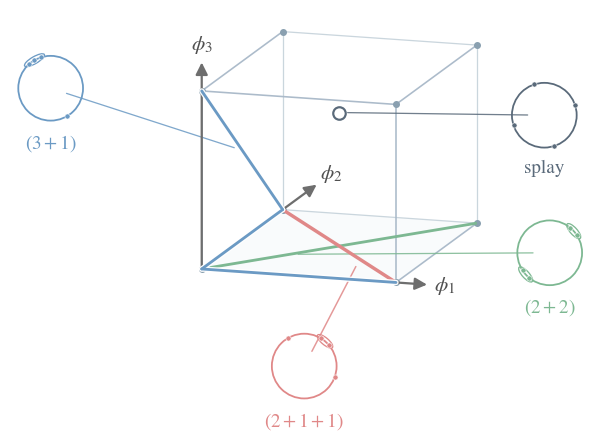

In [3]:
fig, ax = plt.subplots(figsize=(6.6, 3.55), facecolor="white")
ax.set_xlim(-0.52, 1.62)
ax.set_ylim(-0.42, 1.10)
ax.set_aspect("equal")
ax.axis("off")

draw_cube(ax)
draw_markers(ax)

cluster_specs = [
    (r"$(3+1)$", (-0.36, 0.80),
     [(120, 3), (300, 1)], (0, 0.5, 0.5), TRIPLET),
    (r"splay", (1.47, 0.70),
     [(18, 1), (108, 1), (198, 1), (288, 1)], (0.5, 0.5, 0.75), DOT),
    (r"$(2+2)$", (1.49, 0.19),
     [(42, 2), (222, 2)], (0.32, 0.32, 0), PAIRPAIR),
    (r"$(2+1+1)$", (0.58, -0.23),
     [(50, 2), (120, 1), (-20, 1)], (0.68, 0.32, 0), ACCENT),
]

for label, (cx, cy), groups, anchor, color in cluster_specs:
    draw_cluster(ax, cx, cy, r=0.12, groups=groups,
                 label=label, accent_color=color)
    draw_leader(ax, (cx, cy), anchor, color=color,
                lw=0.72 if color == ACCENT else 0.62)

draw_axes(ax)

fig.savefig(OUTPUT, dpi=300, bbox_inches="tight",
            facecolor="white", edgecolor="none")
plt.show()